# Figure S13C — disorder in viruses by host (total fraction across proteome)

Each point is one viral proteome; its value is the total fraction of residues predicted disordered across the whole proteome (TFAP). Viruses are split by host using Virus-Host DB: prokaryote-infecting (archaeal + bacterial hosts), *E. coli*-infecting, eukaryote-infecting and *H. sapiens*-infecting; black bars mark the mean. This is the TFAP counterpart of Figure 3C.

**How it is made.** Reads the host-split tables in `data/viral_proteomes/` in the shared data directory (built from `virushostdb.tsv` with `host_to_tax_id.py`). **These disorder values come from the 2024 metapredict V3 prediction of the UniProt reference proteomes and predate metapredict 3.1.0**; they are not regenerated here. This panel has no significance brackets; the hand-added brackets are on Figure 3C (statistics, on AFPP, in `Fig2C.ipynb`).

**Output:** `figures/figure_S13C.pdf` (drawn vertically; rotated 90° in the assembled figure)

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np

from figtools import apply_style, save_panel, shared_data_path
from viral_disorder import generate_density_based_scatter_data, read_in_tsv

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# seed for the random horizontal jitter of points
JITTER_SEED = 2024
random.seed(JITTER_SEED)
np.random.seed(JITTER_SEED)

# TFAP: disordered residues / all residues, per proteome
DISORDER_VALS = 'total_proteome'

In [2]:
archaea_infecting = read_in_tsv(str(shared_data_path('viral_proteomes', 'archaeal_infecting_viruses.tsv')))
bacteria_infecting = read_in_tsv(str(shared_data_path('viral_proteomes', 'bacterial_infecting_viruses.tsv')))
eukaryotic_infecting = read_in_tsv(str(shared_data_path('viral_proteomes', 'eukaryotic_infecting_viruses.tsv')))
human_infecting = read_in_tsv(str(shared_data_path('viral_proteomes', 'human_infecting_viruses.tsv')))
ecoli_infecting = read_in_tsv(str(shared_data_path('viral_proteomes', 'ecoli_infecting_viruses.tsv')))

# prokaryote-infecting = archaeal + bacterial hosts
prokaryote_infecting = {key: archaea_infecting[key] + bacteria_infecting[key]
                        for key in ['per_protein', 'total_proteome']}

proteomes = {'Prokaryote infecting': prokaryote_infecting, 'E. coli infecting': ecoli_infecting,
             'Eukaryote infecting': eukaryotic_infecting, 'H. sapiens infecting': human_infecting}
for name, values in proteomes.items():
    print(f'{name:22s} n = {len(values[DISORDER_VALS]):5d}  mean = {np.mean(values[DISORDER_VALS]):.3f}')

Prokaryote infecting   n =  4108  mean = 0.111
E. coli infecting      n =   206  mean = 0.098
Eukaryote infecting    n =  2666  mean = 0.183
H. sapiens infecting   n =   211  mean = 0.271


Wrote figures/figure_S13C.pdf


PosixPath('figures/figure_S13C.pdf')

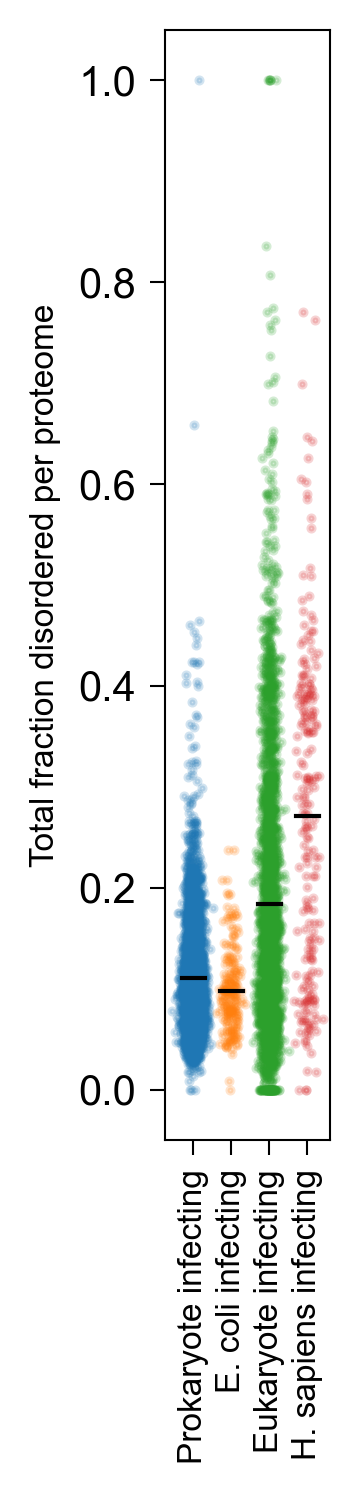

In [3]:
fig, per_prot = plt.subplots(ncols=1, nrows=1, figsize=(1.3, 5.08), dpi=150)
for n, p in enumerate(proteomes):
    x_values, y_values = generate_density_based_scatter_data(proteomes[p][DISORDER_VALS], center=n,
                                                             base_width=0.1, scale_factor=0.05)
    per_prot.scatter(x_values, y_values, marker='.', s=8, alpha=0.2)
    avg = np.mean(y_values)
    per_prot.plot([n - 0.3, n + 0.3], [avg, avg], color='black', linewidth=1)

per_prot.set_xticks(range(len(proteomes)), list(proteomes.keys()), rotation=90, fontsize=8)
per_prot.set_ylabel('Total fraction disordered per proteome', fontsize=8)
plt.tight_layout()
save_panel(fig, 'figure_S13C')